### Drug Effect-vs-Time Curve Simulator

This notebook contains a simulation class `DrugEffectSimulator` that generates synthetic datasets modeling drug response curves over time.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

class DrugEffectSimulator:
    """
    A class to simulate drug effect-vs-time curves.
    The curve rises steeply following a dose at t=0, reaches a defined peak height
    at a specified latency, and decays exponentially back to a baseline.
    """
    def __init__(self, baseline=0.0):
        self.baseline = baseline

    def simulate_curve(self, t, peak_height, peak_latency, decay_half_life):
        """
        Simulates a single drug effect curve over given time points.

        Parameters:
        - t: numpy array of time points (t >= 0)
        - peak_height: The maximum effect size above baseline (Cmax)
        - peak_latency: Time at which the peak effect occurs (Tmax)
        - decay_half_life: Half-life for the elimination/decay phase
        """
        # Prevent division by zero
        if peak_latency <= 0:
            raise ValueError("Peak latency (Tmax) must be greater than 0.")

        # Convert half-life to decay constant (ke)
        ke = np.log(2) / decay_half_life

        # To satisfy peak_latency (Tmax) and have a steep rise,
        # we solve for absorption rate (ka) using the relationship:
        # Tmax = ln(ka/ke) / (ka - ke)
        # We approximate or solve numerically. A robust heuristic is to make ka larger than ke.
        # Let's find ka numerically using a simple root finder for: ka - ke * exp(ka * Tmax - ke * Tmax) = 0
        # For simplicity and stability, we can define ka relative to ke if analytical solving is tricky:
        # Let's iteratively find ka such that Tmax matches.

        from scipy.optimize import fsolve

        def equations(ka):
            return peak_latency - (np.log(ka / ke) / (ka - ke))

        # Initial guess: absorption is 5 times faster than elimination
        ka_guess = 5.0 * ke
        ka = fsolve(equations, ka_guess)[0]

        # Ensure ka is physical
        if ka <= ke:
            ka = ke + 0.1

        # Calculate Bateman curve: C(t) = base + F * (exp(-ke*t) - exp(-ka*t))
        # First, find the unscaled peak value to determine the normalization Factor (F)
        unscaled_peak = np.exp(-ke * peak_latency) - np.exp(-ka * peak_latency)
        F = peak_height / unscaled_peak

        # Generate response
        curve = self.baseline + F * (np.exp(-ke * t) - np.exp(-ka * t))

        # Ensure t < 0 values remain at baseline
        curve = np.where(t >= 0, curve, self.baseline)
        return curve

    def generate_dataset(self, time_limit=24, num_points=100, peak_height=10.0, peak_latency=2.0, decay_half_life=4.0, noise_level=0.2):
        """
        Generates a DataFrame of simulated time and response with optional Gaussian noise.
        """
        t = np.linspace(0, time_limit, num_points)
        clean_signal = self.simulate_curve(t, peak_height, peak_latency, decay_half_life)
        noise = np.random.normal(0, noise_level, size=num_points)
        noisy_signal = clean_signal + noise

        df = pd.DataFrame({
            'Time': t,
            'True_Effect': clean_signal,
            'Observed_Effect': noisy_signal
        })
        return df

,Time,True_Effect,Observed_Effect
0,0.000000,1.000000,0.433055
1,0.161074,5.757860,5.773048
2,0.322148,9.170414,9.028882
3,0.483221,11.590666,10.955156
4,0.644295,13.279550,12.667834


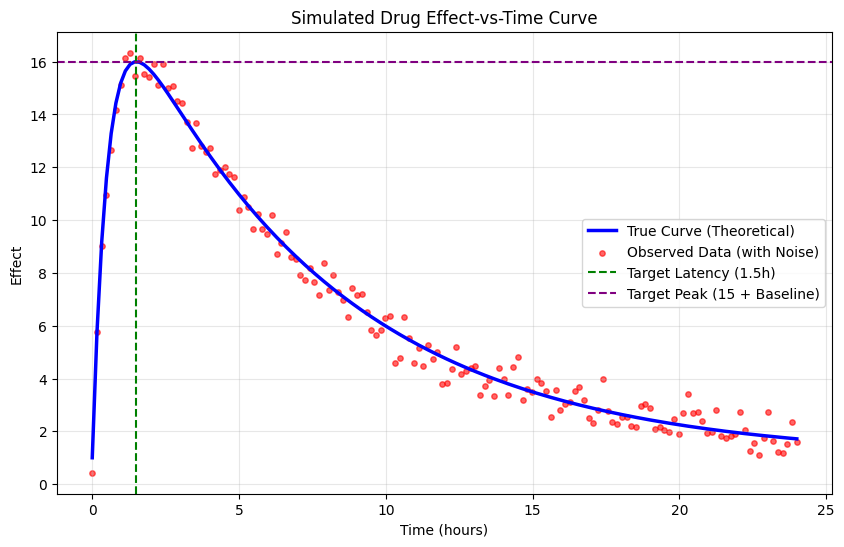

In [ ]:
# Initialize simulator
simulator = DrugEffectSimulator(baseline=1.0)

# Simulate a curve with peak height = 15, peak latency = 1.5 hours, and decay half-life = 5 hours
df_sim = simulator.generate_dataset(
    time_limit=24,
    num_points=150,
    peak_height=15.0,
    peak_latency=1.5,
    decay_half_life=5.0,
    noise_level=0.5
)

# Display first few rows of the generated dataset
display(df_sim.head())

# Plot the results
plt.figure(figsize=(10, 6))
plt.plot(df_sim['Time'], df_sim['True_Effect'], label='True Curve (Theoretical)', color='blue', linewidth=2.5)
plt.scatter(df_sim['Time'], df_sim['Observed_Effect'], label='Observed Data (with Noise)', color='red', alpha=0.6, s=15)
plt.axvline(x=1.5, color='green', linestyle='--', label='Target Latency (1.5h)')
plt.axhline(y=16.0, color='purple', linestyle='--', label='Target Peak (15 + Baseline)')
plt.title('Simulated Drug Effect-vs-Time Curve')
plt.xlabel('Time (hours)')
plt.ylabel('Effect')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()